# 3×4 이미지 비교 표

행: P1 · P2 · P3. 열: 원본 · 10/1 GT · 10/09 JSON GT · 추가/제거.

Case05 고정측 시편003, 원본 Task 641, 000 촬영 방향의 저장 자료를 사용한다.
그림에는 Case 제목·함침율 caption·다운로드 GT 열을 넣지 않는다.
추가/제거는 **10/09 JSON GT − 10/1 GT**다. 주황=추가 미함침, 파랑=제거 미함침, 회색=공통 미함침.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image
from IPython.display import display

candidates = [Path.cwd(), *Path.cwd().parents, Path(r"D:\Code\vision_data")]
ROOT = next(p for p in candidates if (p / "analysis/downloaded_gt_comparison_all_20261009/point_comparison.json").is_file())
SOURCE = ROOT / "analysis/downloaded_gt_comparison_all_20261009"
PANELS = ROOT / "analysis/261012/gt_revision_figures/Case05_specimen003_task641"
OUT = ROOT / "analysis/261012/gt_revision_figures/Case05_specimen003_task641_table"

POINTS = ["P1", "P2", "P3"]
HEADERS = ["원본", "10/1 GT", "10/09 JSON GT", "추가/제거"]
PAD = 5                  # 각 이미지 셀의 흰 여백, native 픽셀 기준
DPI = 300
ADDED_RGB = (189, 120, 72)
REMOVED_RGB = (84, 127, 161)
COMMON_RGB = (153, 153, 153)

font_path = Path("C:/Windows/Fonts/malgun.ttf")
if font_path.is_file():
    font_manager.fontManager.addfont(str(font_path))
    font_name = font_manager.FontProperties(fname=str(font_path)).get_name()
else:
    font_name = "DejaVu Sans"
plt.rcParams.update({"font.family": font_name, "font.size": 11,
                     "figure.facecolor": "white", "savefig.facecolor": "white",
                     "pdf.fonttype": 42, "axes.unicode_minus": False})

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

In [2]:
records_path = SOURCE / "point_comparison.json"
archive_path = SOURCE / "figures/task_641_P123.png"
provenance = json.loads((PANELS / "provenance.json").read_text(encoding="utf-8"))
assert sha256(records_path) == provenance["source_records_sha256"]
assert sha256(archive_path) == provenance["source_archive_sha256"]
records = {r["point"]: r for r in json.loads(records_path.read_text(encoding="utf-8-sig"))
           if r["task_id"] == 641}
assert set(records) == set(POINTS)
assert all(r["case"] == "case05" and r["specimen"] == "03" and r["direction"] == "000"
           for r in records.values())
with Image.open(archive_path) as image:
    archive = np.asarray(image.convert("RGB"))
assert archive.shape == (1150, 1410, 3)

panels = []
measurements = []
source_hashes = {}
exported_hashes = {f["filename"]: f["sha256"] for f in provenance["files"]}
for i, point in enumerate(POINTS):
    row = records[point]
    original_path = PANELS / f"{point}_original.png"
    old_path = PANELS / f"{point}_GT_20261001.png"
    for path in [original_path, old_path]:
        source_hashes[str(path)] = sha256(path)
        assert source_hashes[str(path)] == exported_hashes[path.name]
    with Image.open(original_path) as image:
        original = np.asarray(image.convert("RGB"))
    with Image.open(old_path) as image:
        old_rgb = np.asarray(image.convert("RGB"))
    y = 126 + i * 344
    # 3번째 패널은 직전 10/09 JSON GT. 다운로드 GT 패널은 사용하지 않는다.
    previous_rgb = archive[y:y + 256, 576:576 + 256].copy()
    assert original.shape == old_rgb.shape == previous_rgb.shape == (256, 256, 3)
    assert np.array_equal(original, archive[y:y + 256, 20:20 + 256])
    assert np.array_equal(old_rgb, archive[y:y + 256, 298:298 + 256])
    for mask in [old_rgb, previous_rgb]:
        assert np.isin(mask, [0, 255]).all()
        assert np.array_equal(mask[:, :, 0], mask[:, :, 1])
        assert np.array_equal(mask[:, :, 0], mask[:, :, 2])
    old, previous = old_rgb[:, :, 0] > 0, previous_rgb[:, :, 0] > 0
    assert int(old.sum()) == row["old_exposure_pixels"]
    np.testing.assert_allclose(100 * (1 - previous.mean()), row["previous_gt_pct"])
    added, removed = previous & ~old, old & ~previous
    assert int(added.sum()) == row["added_exposure_pixels"]
    assert int(removed.sum()) == row["removed_exposure_pixels"]
    difference = np.zeros((256, 256, 3), dtype=np.uint8)
    difference[old & previous] = COMMON_RGB
    difference[added] = ADDED_RGB
    difference[removed] = REMOVED_RGB
    panels.append([original, old_rgb, previous_rgb, difference])
    measurements.append({"point": point, "old_exposure_pixels": int(old.sum()),
                         "json_exposure_pixels": int(previous.sum()),
                         "added_pixels": int(added.sum()), "removed_pixels": int(removed.sum())})

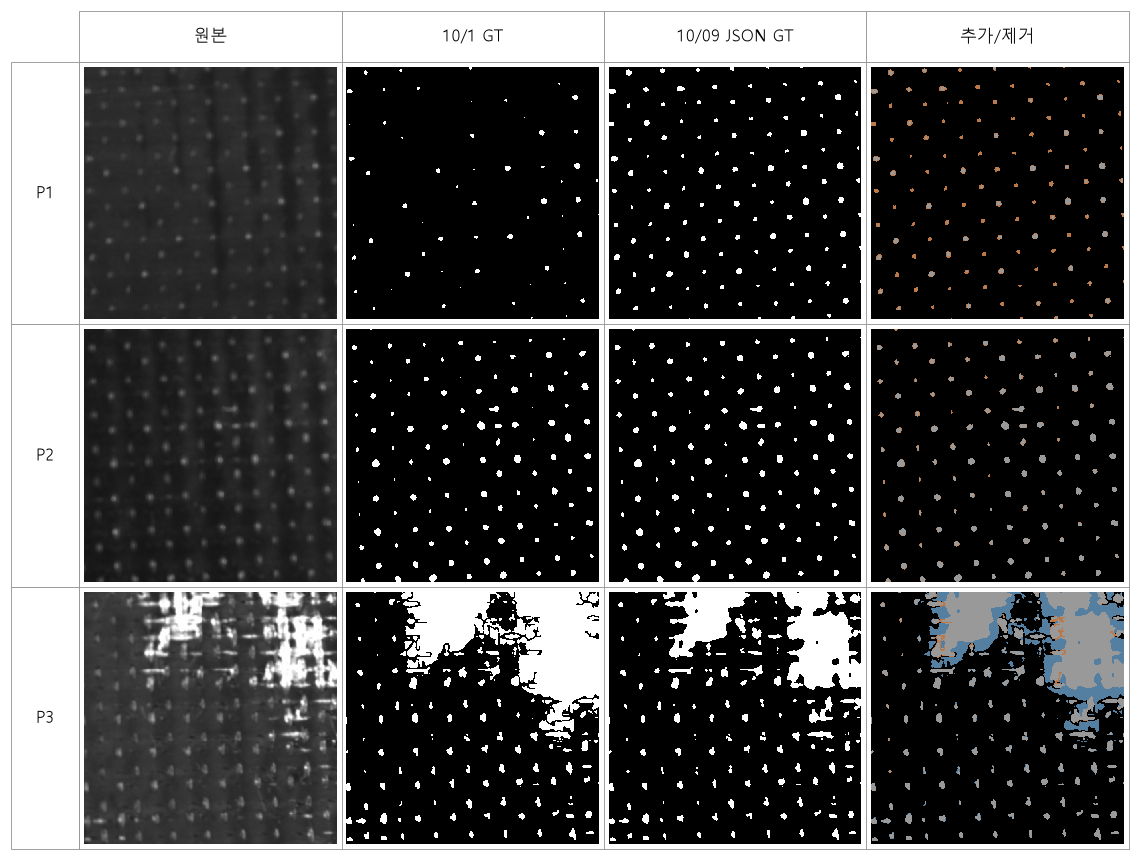

In [3]:
# 12장의 native 배열을 3행×4열로 배치한다. 제목과 이미지별 caption은 없다.
cell_size = 256 + 2 * PAD
canvas = np.full((3 * cell_size, 4 * cell_size, 3), 255, dtype=np.uint8)
for i, row in enumerate(panels):
    for j, panel in enumerate(row):
        y, x = i * cell_size + PAD, j * cell_size + PAD
        canvas[y:y + 256, x:x + 256] = panel
        assert np.array_equal(canvas[y:y + 256, x:x + 256], panel)

fig = plt.figure(figsize=(10.6, 8.15), dpi=110)
ax = fig.add_axes([0.075, 0.03, 0.90, 0.878])
ax.imshow(canvas, extent=(0, 4, 3, 0), interpolation="nearest", aspect="equal")
ax.set_xlim(0, 4)
ax.set_ylim(3, 0)
ax.set_axis_off()

# 열 머리글과 행 이름을 table 셀로 표시한다.
header = ax.table(cellText=[HEADERS], cellLoc="center", bbox=[0, 1, 1, 0.065])
row_names = ax.table(cellText=[[p] for p in POINTS], cellLoc="center", bbox=[-0.065, 0, 0.065, 1])
for table in [header, row_names]:
    table.auto_set_font_size(False)
    table.set_fontsize(11)
    for cell in table.get_celld().values():
        cell.set_facecolor("white")
        cell.set_edgecolor("0.6")
        cell.set_linewidth(0.6)
for x in range(5):
    ax.plot([x, x], [0, 3], color="0.6", linewidth=0.6, clip_on=False)
for y in range(4):
    ax.plot([0, 4], [y, y], color="0.6", linewidth=0.6, clip_on=False)

assert len(panels) == 3 and all(len(row) == 4 for row in panels)
assert not fig._suptitle and not ax.get_title()
OUT.mkdir(parents=True, exist_ok=True)
stem = "Case05_specimen003_P123_3x4"
fig.savefig(OUT / f"{stem}.png", dpi=DPI, bbox_inches="tight", pad_inches=0.04)
fig.savefig(OUT / f"{stem}.pdf", bbox_inches="tight", pad_inches=0.04)
display(fig)
plt.close(fig)

In [4]:
assert all(sha256(path) == digest for path, digest in source_hashes.items())
assert sha256(archive_path) == provenance["source_archive_sha256"]
assert sha256(records_path) == provenance["source_records_sha256"]
verification = {
    "task_id": 641, "case": "Case05", "specimen": "003", "direction": "000",
    "layout": [3, 4], "column_headers": HEADERS, "row_headers": POINTS,
    "global_caption": None, "image_captions": None, "download_gt_column": False,
    "gt_source": "10/09 JSON GT, archived native panel x=576; no downloaded GT panel",
    "source_panel_size_wh": [256, 256], "pixel_counts_match": True,
    "source_hashes": source_hashes, "archive_sha256": sha256(archive_path),
    "records_sha256": sha256(records_path), "measurements": measurements,
    "png": str(OUT / f"{stem}.png"), "pdf": str(OUT / f"{stem}.pdf"),
}
(OUT / "verification.json").write_text(json.dumps(verification, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print(f"PNG: {OUT / f'{stem}.png'}")
print(f"PDF: {OUT / f'{stem}.pdf'}")

PNG: D:\Code\vision_data\analysis\261012\gt_revision_figures\Case05_specimen003_task641_table\Case05_specimen003_P123_3x4.png
PDF: D:\Code\vision_data\analysis\261012\gt_revision_figures\Case05_specimen003_task641_table\Case05_specimen003_P123_3x4.pdf
